In [1]:
!pip install ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo 
 
mushroom = fetch_ucirepo(id=73) 

X = mushroom.data.features 
y = mushroom.data.targets 

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [87]:
X_train.isnull().sum()
(X_train.isnull().sum()/len(X_train)) * 100

cap-shape                    0.000000
cap-surface                  0.000000
cap-color                    0.000000
bruises                      0.000000
odor                         0.000000
gill-attachment              0.000000
gill-spacing                 0.000000
gill-size                    0.000000
gill-color                   0.000000
stalk-shape                  0.000000
stalk-root                  30.281582
stalk-surface-above-ring     0.000000
stalk-surface-below-ring     0.000000
stalk-color-above-ring       0.000000
stalk-color-below-ring       0.000000
veil-type                    0.000000
veil-color                   0.000000
ring-number                  0.000000
ring-type                    0.000000
spore-print-color            0.000000
population                   0.000000
habitat                      0.000000
dtype: float64

In [88]:
X_train['stalk-root'] = X_train['stalk-root'].fillna('unkown')

In [89]:
X_train.duplicated().sum()

np.int64(0)

In [90]:
X_train

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
5249,f,y,y,f,f,f,c,b,g,e,...,k,p,b,p,w,o,l,h,y,g
5781,x,s,p,t,n,f,c,b,e,e,...,s,e,w,p,w,t,e,w,c,w
7586,b,s,g,f,n,f,w,b,w,e,...,s,w,w,p,w,t,p,w,s,g
6181,f,s,n,f,s,f,c,n,b,t,...,k,p,w,p,w,o,e,w,v,d
7338,k,y,n,f,f,f,c,n,b,t,...,k,p,p,p,w,o,e,w,v,p
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6150,x,s,n,f,s,f,c,n,b,t,...,s,p,p,p,w,o,e,w,v,d
5386,x,y,n,f,n,f,w,n,w,e,...,f,w,n,p,w,o,e,w,v,l
1357,f,f,w,f,n,f,w,b,p,t,...,s,w,w,p,w,o,e,k,a,g
2977,x,f,g,t,n,f,c,b,w,t,...,s,g,p,p,w,o,p,n,y,d


In [91]:
for col in X_train.columns:
    print(f'{X_train[col].value_counts()}\n')

cap-shape
x    2937
f    2517
k     653
b     361
s      27
c       4
Name: count, dtype: int64

cap-surface
y    2570
s    2050
f    1876
g       3
Name: count, dtype: int64

cap-color
n    1812
g    1501
e    1180
y     869
w     825
b     133
p     119
c      35
r      15
u      10
Name: count, dtype: int64

bruises
f    3795
t    2704
Name: count, dtype: int64

odor
n    2826
f    1754
y     457
s     450
l     319
a     318
p     194
c     154
m      27
Name: count, dtype: int64

gill-attachment
f    6337
a     162
Name: count, dtype: int64

gill-spacing
c    5456
w    1043
Name: count, dtype: int64

gill-size
b    4518
n    1981
Name: count, dtype: int64

gill-color
b    1367
p    1218
w     970
n     818
g     616
h     585
u     392
k     319
e      78
y      66
o      49
r      21
Name: count, dtype: int64

stalk-shape
t    3678
e    2821
Name: count, dtype: int64

stalk-root
b         3049
unkown    1968
e          887
c          443
r          152
Name: count, dtype: int64



In [92]:
for col in X_train.columns:
    if X_train[col].nunique() == 1:
        print(f'{X_train[col].value_counts()}\n')

veil-type
p    6499
Name: count, dtype: int64



In [93]:
for col in X_train.columns:
    if X_train[col].nunique() == 2:
        print(f'{X_train[col].value_counts()}\n')

bruises
f    3795
t    2704
Name: count, dtype: int64

gill-attachment
f    6337
a     162
Name: count, dtype: int64

gill-spacing
c    5456
w    1043
Name: count, dtype: int64

gill-size
b    4518
n    1981
Name: count, dtype: int64

stalk-shape
t    3678
e    2821
Name: count, dtype: int64



In [94]:
ohe_cols = []

for col in X_train.columns:
    if X_train[col].nunique() > 2:
        ohe_cols.append(col)

ohe_cols

['cap-shape',
 'cap-surface',
 'cap-color',
 'odor',
 'gill-color',
 'stalk-root',
 'stalk-surface-above-ring',
 'stalk-surface-below-ring',
 'stalk-color-above-ring',
 'stalk-color-below-ring',
 'veil-color',
 'ring-number',
 'ring-type',
 'spore-print-color',
 'population',
 'habitat']

In [95]:
X_train = X_train.drop(columns=['veil-type'])

In [96]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

bi_cols = [
    "bruises",
    "gill-attachment",
    "gill-spacing",
    "gill-size",
    "stalk-shape"
]

bi_cats = [
    ["f", "t"],  
    ["a", "f"],  
    ["c", "w"],  
    ["b", "n"], 
    ["e", "t"]  
]

bi_enc = OrdinalEncoder(categories=bi_cats)

X_train[bi_cols] = bi_enc.fit_transform(X_train[bi_cols])
X_train

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
5249,f,y,y,0.0,f,1.0,0.0,0.0,g,0.0,...,k,k,p,b,w,o,l,h,y,g
5781,x,s,p,1.0,n,1.0,0.0,0.0,e,0.0,...,s,s,e,w,w,t,e,w,c,w
7586,b,s,g,0.0,n,1.0,1.0,0.0,w,0.0,...,k,s,w,w,w,t,p,w,s,g
6181,f,s,n,0.0,s,1.0,0.0,1.0,b,1.0,...,k,k,p,w,w,o,e,w,v,d
7338,k,y,n,0.0,f,1.0,0.0,1.0,b,1.0,...,s,k,p,p,w,o,e,w,v,p
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6150,x,s,n,0.0,s,1.0,0.0,1.0,b,1.0,...,s,s,p,p,w,o,e,w,v,d
5386,x,y,n,0.0,n,1.0,1.0,1.0,w,0.0,...,f,f,w,n,w,o,e,w,v,l
1357,f,f,w,0.0,n,1.0,1.0,0.0,p,1.0,...,s,s,w,w,w,o,e,k,a,g
2977,x,f,g,1.0,n,1.0,0.0,0.0,w,1.0,...,s,s,g,p,w,o,p,n,y,d


In [97]:
one_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

enc_val = one_encoder.fit_transform(X_train[ohe_cols])
new_col = one_encoder.get_feature_names_out(ohe_cols)

In [98]:
import pandas as pd

df_enc = pd.DataFrame(enc_val, columns=new_col, index=X_train.index)

X_train = pd.concat([X_train.drop(columns=ohe_cols), df_enc], axis=1)

In [99]:
X_train

,bruises,gill-attachment,gill-spacing,gill-size,stalk-shape,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
5249,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5781,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7586,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
6181,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
7338,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6150,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5386,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1357,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2977,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [100]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()

In [101]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

model_lr = LogisticRegression()

model_lr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [102]:
model_lr.score(X_train, y_train)

0.9998461301738729

In [8]:
import pandas as pd

def clean_data(data):
    data = data.copy()
    data['stalk-root'] = data['stalk-root'].fillna('unkown')
    data = data.drop(columns=['veil-type'])

    data[bi_cols] = bi_enc.transform(data[bi_cols])

    enc_val = one_encoder.transform(data[ohe_cols])
    df_enc = pd.DataFrame(enc_val, columns=new_col, index=data.index)
    data = pd.concat([data.drop(columns=ohe_cols), df_enc], axis=1)
    
    return data

X_test = clean_data(X_test)

model_lr.score(X_test, y_test)

0.9993846153846154

In [110]:
X_train.shape

(6499, 111)

In [119]:
d = X_train.iloc[[5]]
d

,bruises,gill-attachment,gill-spacing,gill-size,stalk-shape,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
3760,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [120]:
model_lr.predict(d)

array(['e'], dtype=object)

In [121]:
y_train.iloc[[5]]

3760    e
Name: poisonous, dtype: str

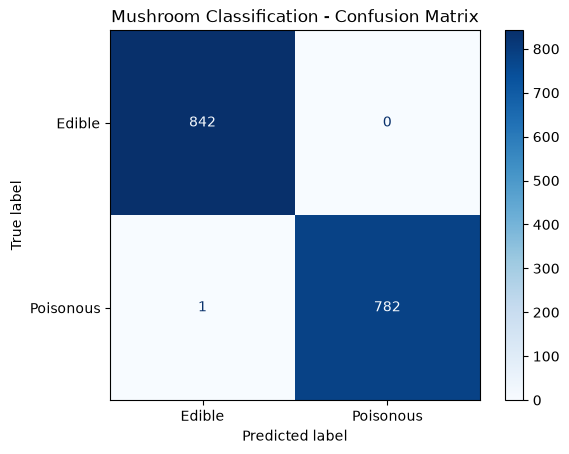

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model_lr.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=["e", "p"])

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Edible", "Poisonous"])

display.plot(cmap="Blues")
plt.title("Mushroom Classification - Confusion Matrix")
plt.show()

In [123]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Edible", "Poisonous"]
))

              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [124]:
from pathlib import Path
import joblib

model_dir = Path("models/mushroom")
model_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": model_lr,
    "binary_encoder": bi_enc,
    "onehot_encoder": one_encoder,
    "binary_columns": bi_cols,
    "onehot_columns": ohe_cols,
    "encoded_columns": new_col,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(model_bundle, model_dir / "mushroom_model.joblib")

['models/mushroom/mushroom_model.joblib']

In [2]:
import joblib

model_bundle = joblib.load("models/mushroom/mushroom_model.joblib")

model_lr = model_bundle["model"]
bi_enc = model_bundle["binary_encoder"]
one_encoder = model_bundle["onehot_encoder"]

bi_cols = model_bundle["binary_columns"]
ohe_cols = model_bundle["onehot_columns"]
new_col = model_bundle["encoded_columns"]

In [15]:
import numpy as np 

y_proba = model_lr.predict_proba(X_test)

poisonous_index = list(model_lr.classes_).index("p")

poisonous_probability = y_proba[:, poisonous_index]

threshold = 0.3

y_pred_adjusted = np.where(poisonous_probability >= threshold, "p", "e")

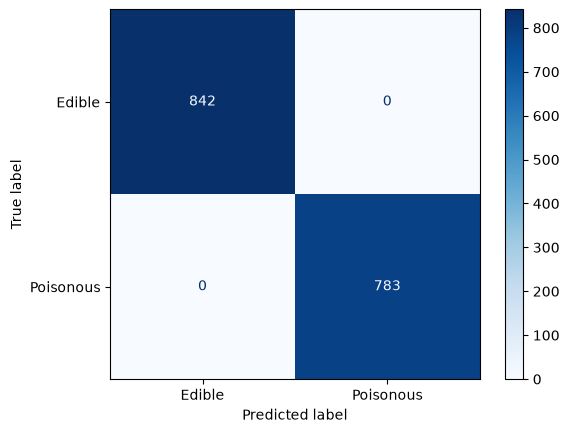

In [14]:
cm = confusion_matrix(y_test, y_pred_adjusted, labels=["e", "p"])

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Edible", "Poisonous"]).plot(cmap="Blues")

plt.show()